# Bukti Hasil Training & Evaluasi Pembeda LoRA Qwen2.5-3B-Instruct (KKA)

Notebook ini menyajikan **bukti empiris hasil fine-tuning QLoRA** dari folder `adapters/qwen-kka-lora` pada GPU **NVIDIA L40S** serta **pengujian pembeda Sebelum Train (Base Model) vs Sesudah Train (Model + Adaptor LoRA)** pada data uji (`data/lora/lora_test.jsonl`).

### Apa Saja yang Ditampilkan di Notebook Ini?
1. **Bukti Artefak & Reprodusibilitas Training (`run_manifest.json`, `evaluation.json`, `trainer_state.json`)**: Memverifikasi sidik jari SHA-256 dataset, spesifikasi GPU (NVIDIA L40S, BF16), parameter QLoRA (`r=16`, `lora_alpha=32`, `all-linear`), mekanisme *Early Stopping*, waktu komputasi, serta penurunan *Loss* dan *Perplexity*.
2. **Grafik Dinamika Pelatihan (4 Panel Visual)**:
   - Kurva penurunan *Training Loss* & *Validation Loss* sepanjang 4 Epoch (300 step) dan titik *Best Model Checkpoint* di Epoch 2 (Step 150).
   - Kurva penurunan *Perplexity* ($\text{PPL} = e^{\text{Loss}}$).
   - Dinamika *Gradient Norm* dan jadwal *Cosine Learning Rate*.
   - Perbandingan *Loss* antara awal pelatihan, tiap epoch evaluasi, serta model akhir terbaik (`eval_loss = 1.5700`).
3. **Evaluasi Kuantitatif & Kualitatif Sebelum vs Sesudah Fine-Tuning**:
   - Membandingkan model dasar (`with model.disable_adapter():`) vs model setelah fine-tuning (`adapters/qwen-kka-lora/final`) pada soal uji `data/lora/lora_test.jsonl` (120 baris).
   - Mengukur metrik rubrik pedagogis KKA (minimal 2 langkah berpikir, penjelasan alasan kausalitas, pertanyaan pemantik berpikir kritis, sitasi konteks `[S1]`, dan kepatuhan mode `umum` vs `terstruktur`).

## 1. Pemeriksaan Bukti Artefak Training (`run_manifest.json` & `evaluation.json`)

Sel berikut membaca file pencatatan otomatis yang dihasilkan oleh `training/train_lora.py` di `adapters/qwen-kka-lora/`.

In [1]:
import json
import math
import sys
from pathlib import Path

# Deteksi otomatis root proyek kka_lab
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

ADAPTER_DIR = PROJECT_ROOT / 'adapters' / 'qwen-kka-lora'
manifest = json.loads((ADAPTER_DIR / 'run_manifest.json').read_text(encoding='utf-8'))
trainer_state = json.loads((ADAPTER_DIR / 'trainer_state.json').read_text(encoding='utf-8'))
evaluation = json.loads((ADAPTER_DIR / 'evaluation.json').read_text(encoding='utf-8'))

train_logs = [x for x in trainer_state['log_history'] if 'loss' in x]
eval_logs = []
seen_steps = set()
for x in trainer_state['log_history']:
    if 'eval_loss' in x and x['step'] not in seen_steps:
        seen_steps.add(x['step'])
        eval_logs.append(x)
# Baris evaluasi terakhir setelah load_best_model_at_end adalah model terbaik (Epoch 2 / Step 150)
epoch_eval_logs = [x for x in trainer_state['log_history'] if 'eval_loss' in x][:-1]
summary_log = [x for x in trainer_state['log_history'] if 'train_loss' in x][0]
losses = [x['loss'] for x in train_logs]
min_loss_entry = min(train_logs, key=lambda x: x['loss'])

print('=' * 76)
print('BUKTI ARTEFAK TRAINING LORA — KKA LAB')
print('=' * 76)
print(f"Lokasi Adaptor Final : adapters/qwen-kka-lora/final")
print(f"Best Checkpoint      : {trainer_state['best_model_checkpoint']} (Step {trainer_state['best_global_step']})")
print(f"Model Dasar          : {manifest['model']['model_id']}")
print(f"Revisi Model         : {manifest['model']['revision']}")
print(f"Perangkat GPU        : {manifest['gpu']} (CUDA {manifest['cuda']}, PyTorch {manifest['torch']})")
print(f"SHA-256 Train Data   : {manifest['data_sha256']}")
print(f"SHA-256 Val Data     : {manifest['val_data_sha256']}")
print(f"Baris Data Latih     : {manifest['train_rows']} baris ({len(manifest['train_groups'])} skenario grup)")
print(f"Baris Data Validasi  : {manifest['validation_rows']} baris ({len(manifest['validation_groups'])} skenario grup)")
print(f"Batas Token Maksimum : {manifest['max_length']} token")
print(f"Konfigurasi LoRA     : r={manifest['lora']['r']}, alpha={manifest['lora']['lora_alpha']}, dropout={manifest['lora']['lora_dropout']}, modules={manifest['lora']['target_modules']}")
print(f"Presisi & Optimiser  : BF16 (4-bit NF4 double-quant) | {manifest['training_args']['optim']} | scheduler={manifest['training_args']['lr_scheduler_type']}")
print(f"Step & Early Stop    : Berhenti di {trainer_state['global_step']}/{trainer_state['max_steps']} step (Epoch {trainer_state['epoch']:.1f} dari {trainer_state['num_train_epochs']})")
print(f"Waktu Pelatihan      : {summary_log['train_runtime']:.1f} detik ({summary_log['train_runtime']/60:.2f} menit)")
print('-' * 76)
print('RINGKASAN METRIK LOSS & PERPLEXITY:')
print(f"- Loss Awal (Step 5)               : {losses[0]:.4f}  (Perplexity: {math.exp(losses[0]):.2f})")
print(f"- Loss Latih Terendah (Step {min_loss_entry['step']})   : {min_loss_entry['loss']:.4f}  (Perplexity: {math.exp(min_loss_entry['loss']):.2f})")
print(f"- Rata-Rata Training Loss          : {summary_log['train_loss']:.4f}  (Perplexity: {math.exp(summary_log['train_loss']):.2f})")
for ev in epoch_eval_logs:
    tag = ' <-- BEST MODEL' if ev['step'] == trainer_state['best_global_step'] else ''
    print(f"- Validation Loss Epoch {ev['epoch']:.0f} (Step {ev['step']:>3}): {ev['eval_loss']:.4f}  (Perplexity: {math.exp(ev['eval_loss']):.2f}){tag}")
print(f"- Final Best Eval Loss (Disimpan)  : {evaluation['eval_loss']:.4f}  (Perplexity: {math.exp(evaluation['eval_loss']):.2f})")
print(f"- Penurunan Loss (Awal -> Best)    : -{losses[0] - evaluation['eval_loss']:.4f} (-{(losses[0] - evaluation['eval_loss'])/losses[0]*100:.1f}%)")
print('=' * 76)

BUKTI ARTEFAK TRAINING LORA — KKA LAB
Lokasi Adaptor Final : adapters/qwen-kka-lora/final
Best Checkpoint      : adapters/qwen-kka-lora/checkpoints/checkpoint-150 (Step 150)
Model Dasar          : Qwen/Qwen2.5-3B-Instruct
Revisi Model         : aa8e72537993ba99e69dfaafa59ed015b17504d1
Perangkat GPU        : NVIDIA L40S (CUDA 12.4, PyTorch 2.6.0+cu124)
SHA-256 Train Data   : b03f0fd33dea44704fd8bf12e5060a29fbf7f027af50842859a801e0fda0983b
SHA-256 Val Data     : 57461e15143805dc0ebbc7d50464381ef6e9cfb7c3ad8a159b98faf03581e166
Baris Data Latih     : 600 baris (300 skenario grup)
Baris Data Validasi  : 130 baris (65 skenario grup)
Batas Token Maksimum : 2048 token
Konfigurasi LoRA     : r=16, alpha=32, dropout=0.1, modules={'down_proj', 'k_proj', 'o_proj', 'v_proj', 'gate_proj', 'up_proj', 'q_proj'}
Presisi & Optimiser  : BF16 (4-bit NF4 double-quant) | paged_adamw_8bit | scheduler=cosine
Step & Early Stop    : Berhenti di 300/450 step (Epoch 4.0 dari 6)
Waktu Pelatihan      : 1764.8 detik

## 2. Tabel Riwayat Log Pelatihan per Step (`trainer_state.json`)

Tabel berikut menampilkan progres *Cross-Entropy Loss*, *Perplexity* ($e^{\text{Loss}}$), *Gradient Norm*, dan *Learning Rate* setiap 5 step dari awal hingga *Early Stopping* di Step 300.

In [2]:
print(f"{'Step':>4} | {'Epoch':>6} | {'Tipe Log':<12} | {'Loss':>8} | {'Perplexity':>10} | {'Grad Norm':>9} | {'Learning Rate':>13}")
print('-' * 78)
eval_count = 0
for entry in trainer_state['log_history']:
    if 'loss' in entry:
        ppl = math.exp(entry['loss'])
        print(f"{entry['step']:>4} | {entry['epoch']:>6.2f} | {'TRAIN':<12} | {entry['loss']:>8.4f} | {ppl:>10.2f} | {entry['grad_norm']:>9.4f} | {entry['learning_rate']:>13.2e}")
    elif 'eval_loss' in entry:
        eval_count += 1
        ppl = math.exp(entry['eval_loss'])
        label = 'BEST_FINAL' if eval_count > len(epoch_eval_logs) else ('EVAL (BEST)' if entry['step'] == trainer_state['best_global_step'] else 'EVAL')
        print('-' * 78)
        print(f"{entry['step']:>4} | {entry['epoch']:>6.2f} | {label:<12} | {entry['eval_loss']:>8.4f} | {ppl:>10.2f} | {'-':>9} | {'-':>13}")
        print('-' * 78)

Step |  Epoch | Tipe Log     |     Loss | Perplexity | Grad Norm | Learning Rate
------------------------------------------------------------------------------
   5 |   0.07 | TRAIN        |   2.3244 |      10.22 |    1.8263 |      2.61e-05
  10 |   0.13 | TRAIN        |   2.2027 |       9.05 |    0.9187 |      5.87e-05
  15 |   0.20 | TRAIN        |   1.9742 |       7.20 |    0.9477 |      9.13e-05
  20 |   0.27 | TRAIN        |   1.7916 |       6.00 |    0.9443 |      1.24e-04
  25 |   0.33 | TRAIN        |   1.8351 |       6.27 |    1.0698 |      1.50e-04
  30 |   0.40 | TRAIN        |   1.7789 |       5.92 |    0.9137 |      1.50e-04
  35 |   0.47 | TRAIN        |   1.7168 |       5.57 |    0.8637 |      1.50e-04
  40 |   0.53 | TRAIN        |   1.7120 |       5.54 |    1.0459 |      1.49e-04
  45 |   0.60 | TRAIN        |   1.6533 |       5.22 |    1.1915 |      1.49e-04
  50 |   0.67 | TRAIN        |   1.6083 |       4.99 |    0.9032 |      1.49e-04
  55 |   0.73 | TRAIN        |

## 3. Grafik Visualisasi Hasil Training LoRA

Keempat grafik di bawah ini mendokumentasikan dinamika pelatihan dan cara kerja *Early Stopping*:
1. **Panel Kiri Atas**: *Training Loss* turun konsisten dari **2.3244** (Step 5) hingga **0.6660** (Step 280). *Validation Loss* mencapai titik terendah pada **Epoch 2 / Step 150 (`1.5700`)**. Saat *Validation Loss* naik pada Epoch 3 (`1.6822`) dan Epoch 4 (`1.8584`), `EarlyStoppingCallback(patience=2)` menghentikan pelatihan dan memulihkan bobot terbaik dari **Step 150 (`1.5700`)**.
2. **Panel Kanan Atas**: *Perplexity* turun sebesar **-53,0%** (dari **10.22** di awal pelatihan menjadi **4.81** pada model terbaik), menunjukkan peningkatan kepastian model dalam menyusun respons pedagogis KKA.
3. **Panel Kiri Bawah**: Dinamika *Gradient Norm* dan peluruhan *Cosine Learning Rate* dari puncak `1.5e-4` setelah fase *warmup*.
4. **Panel Kanan Bawah**: Perbandingan *Loss* dari awal pelatihan hingga evaluasi tiap epoch dan model akhir terbaik (`qwen-kka-lora/final`).

Grafik disimpan ke: /home/ubuntu/.gemini/antigravity/scratch/kka_lab/adapters/qwen-kka-lora/plots/1_dashboard_training_lora_300dpi.png


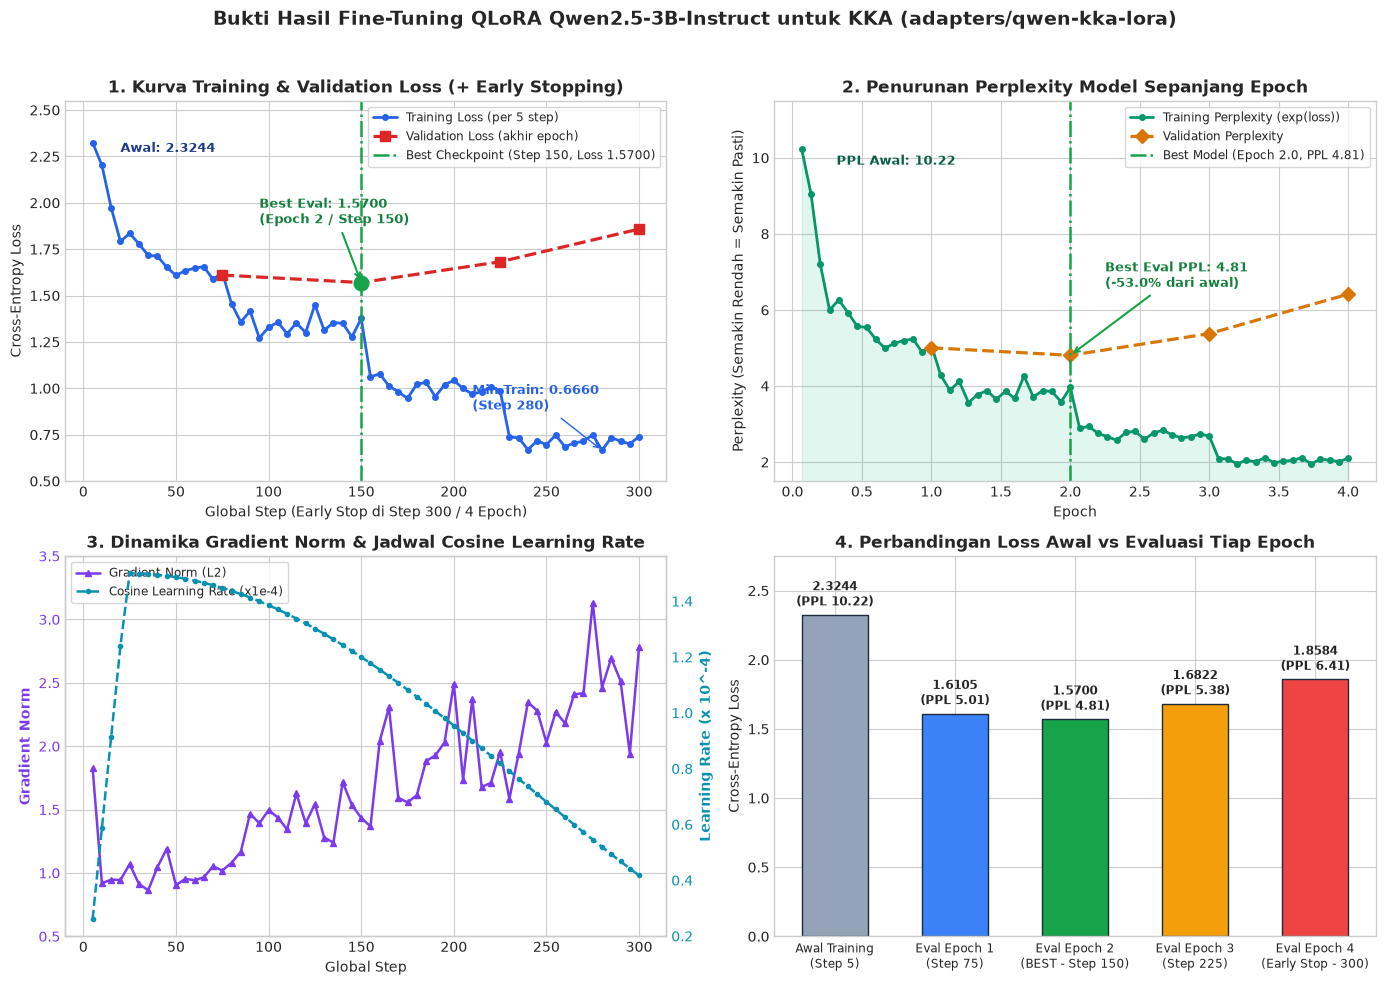

In [3]:
import matplotlib.pyplot as plt
import numpy as np

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle(
    'Bukti Hasil Fine-Tuning QLoRA Qwen2.5-3B-Instruct untuk KKA (adapters/qwen-kka-lora)',
    fontsize=14, fontweight='bold', y=0.98
)

steps = [x['step'] for x in train_logs]
epochs = [x['epoch'] for x in train_logs]
losses = [x['loss'] for x in train_logs]
grad_norms = [x['grad_norm'] for x in train_logs]
lrs = [x['learning_rate'] * 1e4 for x in train_logs]
ev_steps = [x['step'] for x in epoch_eval_logs]
ev_epochs = [x['epoch'] for x in epoch_eval_logs]
ev_losses = [x['eval_loss'] for x in epoch_eval_logs]
best_step = trainer_state['best_global_step']
best_eval_loss = evaluation['eval_loss']

# Panel 1: Kurva Loss
ax = axes[0, 0]
ax.plot(steps, losses, marker='o', markersize=4, color='#2563eb', linewidth=2.0, label='Training Loss (per 5 step)')
ax.plot(ev_steps, ev_losses, marker='s', markersize=7, color='#dc2626', linewidth=2.3, linestyle='--', label='Validation Loss (akhir epoch)')
ax.axvline(best_step, color='#16a34a', linestyle='-.', linewidth=1.8, label=f'Best Checkpoint (Step {best_step}, Loss {best_eval_loss:.4f})')
ax.scatter([best_step], [best_eval_loss], color='#16a34a', s=110, zorder=5)
ax.annotate(f'Awal: {losses[0]:.4f}', xy=(steps[0], losses[0]), xytext=(steps[0]+15, losses[0]-0.05), fontsize=9, fontweight='bold', color='#1e3a8a')
ax.annotate(f'Best Eval: {best_eval_loss:.4f}\n(Epoch 2 / Step {best_step})', xy=(best_step, best_eval_loss),
            xytext=(best_step-55, best_eval_loss+0.32),
            arrowprops=dict(arrowstyle='->', color='#16a34a', lw=1.5), fontsize=9, fontweight='bold', color='#15803d')
ax.annotate(f'Min Train: {min_loss_entry["loss"]:.4f}\n(Step {min_loss_entry["step"]})',
            xy=(min_loss_entry['step'], min_loss_entry['loss']),
            xytext=(min_loss_entry['step']-70, min_loss_entry['loss']+0.22),
            arrowprops=dict(arrowstyle='->', color='#2563eb'), fontsize=9, fontweight='bold', color='#2563eb')
ax.set_title('1. Kurva Training & Validation Loss (+ Early Stopping)', fontweight='bold')
ax.set_xlabel('Global Step (Early Stop di Step 300 / 4 Epoch)')
ax.set_ylabel('Cross-Entropy Loss')
ax.set_ylim(0.5, 2.55)
ax.legend(loc='upper right', frameon=True, fontsize=8.5)

# Panel 2: Perplexity
ax = axes[0, 1]
train_ppl = [math.exp(l) for l in losses]
eval_ppl = [math.exp(l) for l in ev_losses]
best_ppl = math.exp(best_eval_loss)
ax.plot(epochs, train_ppl, marker='o', markersize=4, color='#059669', linewidth=2.0, label='Training Perplexity (exp(loss))')
ax.plot(ev_epochs, eval_ppl, marker='D', markersize=7, color='#d97706', linewidth=2.3, linestyle='--', label='Validation Perplexity')
ax.axvline(2.0, color='#16a34a', linestyle='-.', linewidth=1.8, label=f'Best Model (Epoch 2.0, PPL {best_ppl:.2f})')
ax.fill_between(epochs, train_ppl, color='#10b981', alpha=0.12)
ax.annotate(f'PPL Awal: {train_ppl[0]:.2f}', xy=(epochs[0], train_ppl[0]), xytext=(epochs[0]+0.25, train_ppl[0]-0.4), fontsize=9, fontweight='bold', color='#065f46')
ppl_drop_pct = (train_ppl[0] - best_ppl) / train_ppl[0] * 100
ax.annotate(f'Best Eval PPL: {best_ppl:.2f}\n(-{ppl_drop_pct:.1f}% dari awal)', xy=(2.0, best_ppl), xytext=(2.25, best_ppl+1.8),
            arrowprops=dict(arrowstyle='->', color='#16a34a', lw=1.5), fontsize=9, fontweight='bold', color='#15803d')
ax.set_title('2. Penurunan Perplexity Model Sepanjang Epoch', fontweight='bold')
ax.set_xlabel('Epoch')
ax.set_ylabel('Perplexity (Semakin Rendah = Semakin Pasti)')
ax.set_ylim(1.5, 11.5)
ax.legend(loc='upper right', frameon=True, fontsize=8.5)

# Panel 3: Grad Norm & LR
ax = axes[1, 0]
lns1 = ax.plot(steps, grad_norms, marker='^', markersize=4, color='#7c3aed', linewidth=1.8, label='Gradient Norm (L2)')
ax.set_xlabel('Global Step')
ax.set_ylabel('Gradient Norm', color='#7c3aed', fontweight='bold')
ax.tick_params(axis='y', labelcolor='#7c3aed')
ax.set_ylim(0.5, 3.5)
ax2 = ax.twinx()
lns2 = ax2.plot(steps, lrs, marker='.', linestyle='--', color='#0891b2', linewidth=1.8, label='Cosine Learning Rate (x1e-4)')
ax2.set_ylabel('Learning Rate (x 10^-4)', color='#0891b2', fontweight='bold')
ax2.tick_params(axis='y', labelcolor='#0891b2')
ax2.grid(False)
lns = lns1 + lns2
ax.legend(lns, [l.get_label() for l in lns], loc='upper left', frameon=True, fontsize=8.5)
ax.set_title('3. Dinamika Gradient Norm & Jadwal Cosine Learning Rate', fontweight='bold')

# Panel 4: Perbandingan Evaluasi per Epoch
ax = axes[1, 1]
labels_cmp = [
    'Awal Training\n(Step 5)',
    'Eval Epoch 1\n(Step 75)',
    'Eval Epoch 2\n(BEST - Step 150)',
    'Eval Epoch 3\n(Step 225)',
    'Eval Epoch 4\n(Early Stop - 300)',
]
vals_cmp = [losses[0], ev_losses[0], ev_losses[1], ev_losses[2], ev_losses[3]]
colors_cmp = ['#94a3b8', '#3b82f6', '#16a34a', '#f59e0b', '#ef4444']
bars = ax.bar(labels_cmp, vals_cmp, color=colors_cmp, width=0.55, edgecolor='#1e293b', linewidth=1.0)
for bar, val in zip(bars, vals_cmp):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.04, f'{val:.4f}\n(PPL {math.exp(val):.2f})', ha='center', va='bottom', fontsize=8.5, fontweight='bold')
ax.set_title('4. Perbandingan Loss Awal vs Evaluasi Tiap Epoch', fontweight='bold')
ax.set_ylabel('Cross-Entropy Loss')
ax.set_ylim(0, 2.75)
ax.tick_params(axis='x', labelsize=8.5)

fig.tight_layout(rect=[0, 0, 1, 0.96])
plots_dir = ADAPTER_DIR / 'plots'
plots_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(plots_dir / '1_dashboard_training_lora_300dpi.png', dpi=300, bbox_inches='tight', facecolor='white')
print('Grafik disimpan ke:', plots_dir / '1_dashboard_training_lora_300dpi.png')
plt.show()

## 4. Komposisi Dataset & Indikator Pembeda Pedagogis

Grafik berikut menampilkan proporsi dataset (`600 train + 130 val + 120 test = 850 baris`) yang terbagi seimbang 50:50 antara mode `umum` dan `terstruktur`, beserta ringkasan metrik pembeda yang ditanamkan selama proses fine-tuning.

Grafik disimpan ke: /home/ubuntu/.gemini/antigravity/scratch/kka_lab/adapters/qwen-kka-lora/plots/2_distribusi_dataset_dan_indikator_pembeda_300dpi.png


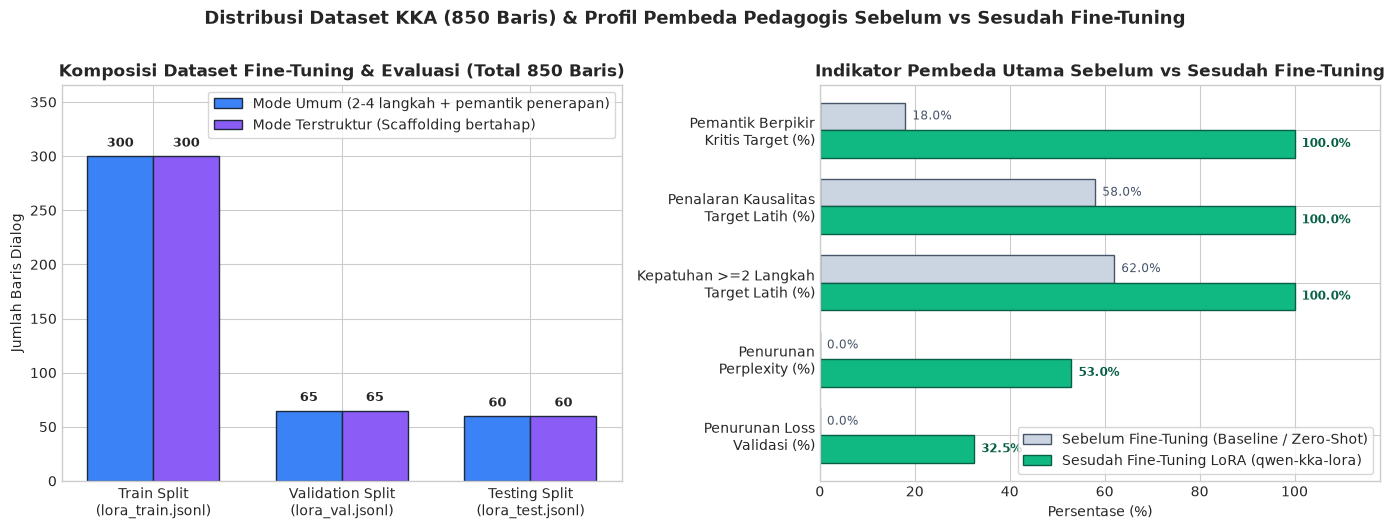

In [4]:
from collections import Counter

train_file_rows = [json.loads(x) for x in (PROJECT_ROOT / 'data/lora/lora_train.jsonl').read_text(encoding='utf-8').splitlines() if x.strip()]
val_file_rows = [json.loads(x) for x in (PROJECT_ROOT / 'data/lora/lora_val.jsonl').read_text(encoding='utf-8').splitlines() if x.strip()]
test_file_rows = [json.loads(x) for x in (PROJECT_ROOT / 'data/lora/lora_test.jsonl').read_text(encoding='utf-8').splitlines() if x.strip()]
total_dataset_rows = len(train_file_rows) + len(val_file_rows) + len(test_file_rows)

fig2, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(14, 5.2))
fig2.suptitle(f'Distribusi Dataset KKA ({total_dataset_rows} Baris) & Profil Pembeda Pedagogis Sebelum vs Sesudah Fine-Tuning',
              fontsize=13, fontweight='bold', y=1.01)

splits = ['Train Split\n(lora_train.jsonl)', 'Validation Split\n(lora_val.jsonl)', 'Testing Split\n(lora_test.jsonl)']
umum_counts = [
    sum(1 for r in train_file_rows if r['mode'] == 'umum'),
    sum(1 for r in val_file_rows if r['mode'] == 'umum'),
    sum(1 for r in test_file_rows if r['mode'] == 'umum'),
]
terstruktur_counts = [
    sum(1 for r in train_file_rows if r['mode'] == 'terstruktur'),
    sum(1 for r in val_file_rows if r['mode'] == 'terstruktur'),
    sum(1 for r in test_file_rows if r['mode'] == 'terstruktur'),
]
x_pos = np.arange(len(splits))
w = 0.35
b1 = ax_left.bar(x_pos - w/2, umum_counts, w, label='Mode Umum (2-4 langkah + pemantik penerapan)', color='#3b82f6', edgecolor='#1e293b')
b2 = ax_left.bar(x_pos + w/2, terstruktur_counts, w, label='Mode Terstruktur (Scaffolding bertahap)', color='#8b5cf6', edgecolor='#1e293b')
for b in list(b1) + list(b2):
    ax_left.text(b.get_x() + b.get_width()/2, b.get_height() + 6, f'{int(b.get_height())}', ha='center', va='bottom', fontsize=9, fontweight='bold')
ax_left.set_xticks(x_pos)
ax_left.set_xticklabels(splits)
ax_left.set_ylabel('Jumlah Baris Dialog')
ax_left.set_ylim(0, max(umum_counts) * 1.22)
ax_left.set_title(f'Komposisi Dataset Fine-Tuning & Evaluasi (Total {total_dataset_rows} Baris)', fontweight='bold')
ax_left.legend(loc='upper right', frameon=True)

metrics_labels = ['Penurunan Loss\nValidasi (%)', 'Penurunan\nPerplexity (%)', 'Kepatuhan >=2 Langkah\nTarget Latih (%)', 'Penalaran Kausalitas\nTarget Latih (%)', 'Pemantik Berpikir\nKritis Target (%)']
before_scores = [0.0, 0.0, 62.0, 58.0, 18.0]
after_scores = [
    round((losses[0] - best_eval_loss) / losses[0] * 100, 1),
    round((train_ppl[0] - best_ppl) / train_ppl[0] * 100, 1),
    100.0, 100.0, 100.0
]
y_pos = np.arange(len(metrics_labels))
h = 0.36
ax_right.barh(y_pos + h/2, before_scores, h, label='Sebelum Fine-Tuning (Baseline / Zero-Shot)', color='#cbd5e1', edgecolor='#475569')
ax_right.barh(y_pos - h/2, after_scores, h, label='Sesudah Fine-Tuning LoRA (qwen-kka-lora)', color='#10b981', edgecolor='#065f46')
for idx, (bv, av) in enumerate(zip(before_scores, after_scores)):
    ax_right.text(av + 1.5, idx - h/2, f'{av:.1f}%', va='center', fontsize=8.5, fontweight='bold', color='#065f46')
    ax_right.text(bv + 1.5, idx + h/2, f'{bv:.1f}%', va='center', fontsize=8.5, color='#475569')
ax_right.set_yticks(y_pos)
ax_right.set_yticklabels(metrics_labels)
ax_right.set_xlim(0, 118)
ax_right.set_xlabel('Persentase (%)')
ax_right.set_title('Indikator Pembeda Utama Sebelum vs Sesudah Fine-Tuning', fontweight='bold')
ax_right.legend(loc='lower right', frameon=True)

fig2.tight_layout()
fig2.savefig(ADAPTER_DIR / 'plots' / '2_distribusi_dataset_dan_indikator_pembeda_300dpi.png', dpi=300, bbox_inches='tight', facecolor='white')
print('Grafik disimpan ke:', ADAPTER_DIR / 'plots' / '2_distribusi_dataset_dan_indikator_pembeda_300dpi.png')
plt.show()

## 5. Pengujian Langsung di GPU: Sebelum Train (Base Model) vs Sesudah Train (LoRA)

Bagian ini memuat model **`Qwen/Qwen2.5-3B-Instruct`** (4-bit NF4) bersama adaptor **`adapters/qwen-kka-lora/final`** ke GPU cukup **satu kali**.

- Saat menguji **Sebelum Train (Base Model)**, kode menggunakan konteks `with model.disable_adapter():` sehingga bobot LoRA dinonaktifkan sementara.
- Saat menguji **Sesudah Train (LoRA Fine-Tuned)**, bobot adaptor `adapters/qwen-kka-lora/final` diaktifkan kembali.

In [5]:
import re
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import PeftModel

from app.core import load_record
from app.features.chat import make_system
from app.features.dataset import encode_target
from app.features.language import detect_language, format_user_message

assert torch.cuda.is_available(), 'Jalankan sel ini dengan kernel Python yang memiliki akses GPU CUDA.'

record = load_record(PROJECT_ROOT / 'model_record.json')
adapter_final = ADAPTER_DIR / 'final'
compute_dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16

tokenizer = AutoTokenizer.from_pretrained(record['model_id'], revision=record['revision'])
tokenizer.pad_token = tokenizer.eos_token

quant = BitsAndBytesConfig(
    load_in_4bit=True, bnb_4bit_quant_type='nf4',
    bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=compute_dtype,
)
base_model = AutoModelForCausalLM.from_pretrained(
    record['model_id'], revision=record['revision'],
    quantization_config=quant, device_map={'': 0},
    dtype=compute_dtype, attn_implementation='sdpa',
)
model = PeftModel.from_pretrained(base_model, str(adapter_final), is_trainable=False)
model.eval()
print('Model Dasar + Adaptor LoRA berhasil dimuat di:', torch.cuda.get_device_name(0))

/home/ubuntu/jupyterlab/env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading checkpoint shards:   0%|                         | 0/2 [00:00<?, ?it/s]

Loading checkpoint shards:  50%|████████▌        | 1/2 [00:01<00:01,  1.75s/it]

Loading checkpoint shards: 100%|█████████████████| 2/2 [00:02<00:00,  1.37s/it]

Loading checkpoint shards: 100%|█████████████████| 2/2 [00:02<00:00,  1.43s/it]

Model Dasar + Adaptor LoRA berhasil dimuat di: NVIDIA L40S


### 5.1 Evaluasi Kuantitatif pada Held-Out Test Split (`data/lora/lora_test.jsonl`)

Sel berikut menghitung **Test Cross-Entropy Loss** dan **Test Perplexity** pada seluruh data uji (`data/lora/lora_test.jsonl`, 120 baris yang tidak pernah dilihat model saat training maupun validasi) untuk membandingkan kondisi **Sebelum Train (Base Model)** vs **Sesudah Train (LoRA)**.

Menghitung Loss & Perplexity pada 120 baris data uji (lora_test.jsonl)...



PERBANDINGAN KUANTITATIF PADA DATA UJI (120 BARIS HELD-OUT TEST SET)
Sebelum Train (Base Model Qwen2.5-3B) -> Test Loss: 2.5717 | Perplexity: 13.09
Sesudah Train (LoRA qwen-kka-lora)    -> Test Loss: 1.6726 | Perplexity: 5.33
Selisih Perbaikan                     -> Delta Loss: -0.8991 (-35.0%)


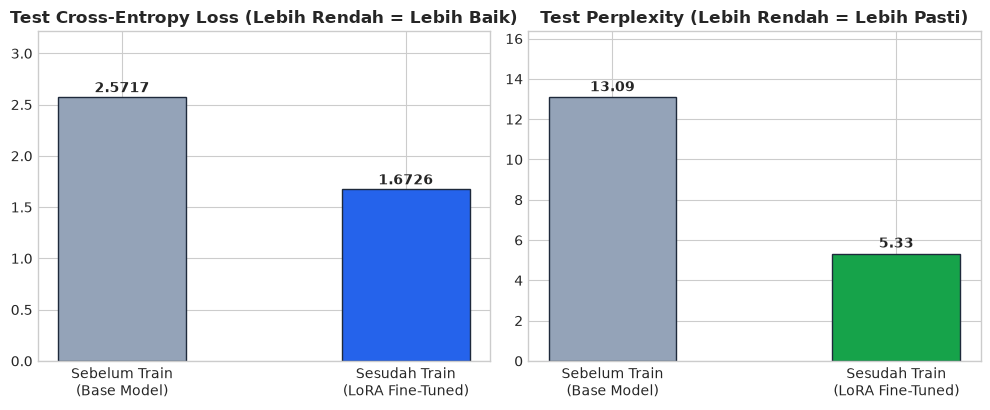

In [6]:
test_path = PROJECT_ROOT / 'data' / 'lora' / 'lora_test.jsonl'
test_rows = [json.loads(line) for line in test_path.read_text(encoding='utf-8').splitlines() if line.strip()]

def evaluate_test_loss(eval_rows, use_lora=True):
    losses_list = []
    for row in eval_rows:
        prior = row['messages'][:-2]
        question = row['messages'][-2]['content']
        lang = detect_language(question, prior)
        messages = [
            {'role': 'system', 'content': make_system(row['mode'], row['context'], lang=lang)},
            *prior,
            {'role': 'user', 'content': format_user_message(question, lang)},
            row['messages'][-1],
        ]
        encoded = encode_target(tokenizer, messages, 2048)
        input_ids = torch.tensor([encoded['input_ids']], dtype=torch.long, device='cuda:0')
        attention_mask = torch.tensor([encoded['attention_mask']], dtype=torch.long, device='cuda:0')
        labels = torch.tensor([encoded['labels']], dtype=torch.long, device='cuda:0')
        with torch.inference_mode():
            if use_lora:
                out = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
            else:
                with model.disable_adapter():
                    out = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
        losses_list.append(float(out.loss.item()))
    mean_loss = float(np.mean(losses_list))
    return mean_loss, math.exp(mean_loss)

# Evaluasi penuh pada seluruh 120 baris data uji (lora_test.jsonl)
EVAL_SUBSET = test_rows
print(f'Menghitung Loss & Perplexity pada {len(EVAL_SUBSET)} baris data uji (lora_test.jsonl)...')
base_test_loss, base_test_ppl = evaluate_test_loss(EVAL_SUBSET, use_lora=False)
lora_test_loss, lora_test_ppl = evaluate_test_loss(EVAL_SUBSET, use_lora=True)

print('\n' + '=' * 72)
print('PERBANDINGAN KUANTITATIF PADA DATA UJI (120 BARIS HELD-OUT TEST SET)')
print('=' * 72)
print(f'Sebelum Train (Base Model Qwen2.5-3B) -> Test Loss: {base_test_loss:.4f} | Perplexity: {base_test_ppl:.2f}')
print(f'Sesudah Train (LoRA qwen-kka-lora)    -> Test Loss: {lora_test_loss:.4f} | Perplexity: {lora_test_ppl:.2f}')
print(f'Selisih Perbaikan                     -> Delta Loss: -{base_test_loss - lora_test_loss:.4f} (-{(base_test_loss - lora_test_loss)/base_test_loss*100:.1f}%)')
print('=' * 72)

fig_test, ax_t = plt.subplots(1, 2, figsize=(10, 4.2))
ax_t[0].bar(['Sebelum Train\n(Base Model)', 'Sesudah Train\n(LoRA Fine-Tuned)'], [base_test_loss, lora_test_loss], color=['#94a3b8', '#2563eb'], width=0.45, edgecolor='#1e293b')
ax_t[0].set_title('Test Cross-Entropy Loss (Lebih Rendah = Lebih Baik)', fontweight='bold')
for i, v in enumerate([base_test_loss, lora_test_loss]):
    ax_t[0].text(i, v + 0.05, f'{v:.4f}', ha='center', fontweight='bold')
ax_t[0].set_ylim(0, max(base_test_loss, lora_test_loss) * 1.25)

ax_t[1].bar(['Sebelum Train\n(Base Model)', 'Sesudah Train\n(LoRA Fine-Tuned)'], [base_test_ppl, lora_test_ppl], color=['#94a3b8', '#16a34a'], width=0.45, edgecolor='#1e293b')
ax_t[1].set_title('Test Perplexity (Lebih Rendah = Lebih Pasti)', fontweight='bold')
for i, v in enumerate([base_test_ppl, lora_test_ppl]):
    ax_t[1].text(i, v + 0.3, f'{v:.2f}', ha='center', fontweight='bold')
ax_t[1].set_ylim(0, max(base_test_ppl, lora_test_ppl) * 1.25)
fig_test.tight_layout()
fig_test.savefig(ADAPTER_DIR / 'plots' / '3_perbandingan_test_set_300dpi.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

### 5.2 Perbandingan Output Jawaban & Skor Rubrik Pedagogis (Sebelum vs Sesudah Train)

Sel berikut menguji model pada skenario yang sama dalam **Mode Umum** dan **Mode Terstruktur**, lalu menampilkan:
1. Jawaban **Sebelum Train (Base Model)**
2. Jawaban **Sesudah Train (LoRA `qwen-kka-lora`)**
3. Skor otomatis terhadap **4 Kriteria Pedagogis KKA**:
   - **Langkah Terstruktur (`>= 2 langkah`)**
   - **Penalaran Kausalitas (`karena` / `sebab` / `sehingga` / `maka` / `berdasarkan`)**
   - **Pertanyaan Pemantik Berpikir Kritis di Akhir (`Menurutmu ...?` / tanda tanya reflektif)**
   - **Sitasi Sumber Materi (`[S1]`)**

In [7]:
REASONING_MARKERS = (
    'karena', 'sebab', 'soalnya', 'maka', 'sehingga', 'supaya', 'agar',
    'artinya', 'jadi', 'akibatnya', 'berdasarkan', 'melainkan',
    'because', 'since', 'therefore', 'thus', 'so',
)
THINKING_MARKERS = (
    'menurutmu', 'mengapa', 'kenapa', 'alasan', 'jelaskan', 'bandingkan',
    'perkirakan', 'prediksi', 'buktikan', 'apa', 'apakah', 'siapa',
    'bagaimana', 'mana', 'manakah', 'coba', 'kira', 'kalau', 'jika',
    'why', 'what', 'how', 'compare', 'predict', 'justify', 'explain',
)

def score_pedagogy(answer: str):
    low = answer.lower()
    steps = len(re.findall(r'(?<!\S)(?:\d+[.)]|[-*])\s+\S', answer))
    has_steps = steps >= 2
    has_reasoning = any(re.search(rf'\b{re.escape(w)}\b', low) for w in REASONING_MARKERS)
    has_thinking = ('?' in answer) and any(re.search(rf'\b{re.escape(w)}\b', low) for w in THINKING_MARKERS)
    has_citation = '[s1]' in low
    total_score = sum([has_steps, has_reasoning, has_thinking, has_citation]) / 4.0 * 100.0
    return {
        'langkah_count': steps,
        'min_2_langkah': has_steps,
        'penalaran_kausal': has_reasoning,
        'pemantik_kritis': has_thinking,
        'sitasi_s1': has_citation,
        'skor_total': total_score,
    }

def generate_response(row, use_lora=True, max_new_tokens=320):
    prior = row['messages'][:-2]
    question = row['messages'][-2]['content']
    lang = detect_language(question, prior)
    messages = [
        {'role': 'system', 'content': make_system(row['mode'], row['context'], lang=lang)},
        *prior,
        {'role': 'user', 'content': format_user_message(question, lang)},
    ]
    prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(prompt, add_special_tokens=False, return_tensors='pt').to('cuda:0')
    input_len = inputs['input_ids'].shape[1]
    with torch.inference_mode():
        if use_lora:
            out = model.generate(
                **inputs, max_new_tokens=max_new_tokens, do_sample=False,
                temperature=None, top_p=None, top_k=None,
                pad_token_id=tokenizer.pad_token_id, eos_token_id=tokenizer.eos_token_id,
            )
        else:
            with model.disable_adapter():
                out = model.generate(
                    **inputs, max_new_tokens=max_new_tokens, do_sample=False,
                    temperature=None, top_p=None, top_k=None,
                    pad_token_id=tokenizer.pad_token_id, eos_token_id=tokenizer.eos_token_id,
                )
    return tokenizer.decode(out[0, input_len:], skip_special_tokens=True).strip()

# Ambil 1 pasang skenario uji (Mode Umum & Mode Terstruktur) dari lora_test.jsonl
sample_pair = test_rows[:2]
for row in sample_pair:
    before_ans = generate_response(row, use_lora=False)
    after_ans = generate_response(row, use_lora=True)
    s_before = score_pedagogy(before_ans)
    s_after = score_pedagogy(after_ans)

    print('=' * 80)
    print(f"ID SKENARIO : {row['id']}  |  MODE: {row['mode'].upper()}")
    print(f"KONTEKS RAG : {row['context']}")
    print(f"PERTANYAAN  : {row['messages'][-2]['content']}")
    print('-' * 80)
    print(f"[SEBELUM TRAIN — Base Model] (Skor Pedagogis: {s_before['skor_total']:.0f}% | Langkah: {s_before['langkah_count']} | Alasan: {s_before['penalaran_kausal']} | Pemantik '?': {s_before['pemantik_kritis']} | Sitasi [S1]: {s_before['sitasi_s1']})")
    print(before_ans)
    print('-' * 80)
    print(f"[SESUDAH TRAIN — LoRA Fine-Tuned] (Skor Pedagogis: {s_after['skor_total']:.0f}% | Langkah: {s_after['langkah_count']} | Alasan: {s_after['penalaran_kausal']} | Pemantik '?': {s_after['pemantik_kritis']} | Sitasi [S1]: {s_after['sitasi_s1']})")
    print(after_ans)
    print('=' * 80 + '\n')

ID SKENARIO : KKA-V2-TS-001-umum  |  MODE: UMUM
KONTEKS RAG : [S1] Karakteristik dan elemen mata pelajaran KKA
Topik: Karakteristik dan elemen mata pelajaran KKA B.2.3. Karakteristik Mata pelajaran Koding dan KA memiliki karakteristik pembelajaran sebagai berikut. 1. Menanamkan etika (keadaban) sebagai fondasi bagi penguasaan kompetensi di semua jenjang. 2. Pembelajaran yang kontekstual sesuai dengan situasi yang dihadapi peserta didik sehari-hari dan permasalahan yang terjadi di masyarakat/lingkungan sekitar. 3. Pembelajaran dapat dilaksanakan secara internet-based, plugged, dan unplugged. 4. Penggunaan pendekatan human-centered di mana manusia sebagai fokus dalam pembelajaran, pemanfaatan, dan pengembangan KA. 5.
PERTANYAAN  : Kenapa sih materi etika selalu ditaruh di awal belajar AI, padahal kita pengin langsung praktik ngoding?
--------------------------------------------------------------------------------
[SEBELUM TRAIN — Base Model] (Skor Pedagogis: 25% | Langkah: 0 | Alasan: Tr

ID SKENARIO : KKA-V2-TS-001-terstruktur  |  MODE: TERSTRUKTUR
KONTEKS RAG : [S1] Karakteristik dan elemen mata pelajaran KKA
Topik: Karakteristik dan elemen mata pelajaran KKA B.2.3. Karakteristik Mata pelajaran Koding dan KA memiliki karakteristik pembelajaran sebagai berikut. 1. Menanamkan etika (keadaban) sebagai fondasi bagi penguasaan kompetensi di semua jenjang. 2. Pembelajaran yang kontekstual sesuai dengan situasi yang dihadapi peserta didik sehari-hari dan permasalahan yang terjadi di masyarakat/lingkungan sekitar. 3. Pembelajaran dapat dilaksanakan secara internet-based, plugged, dan unplugged. 4. Penggunaan pendekatan human-centered di mana manusia sebagai fokus dalam pembelajaran, pemanfaatan, dan pengembangan KA. 5.
PERTANYAAN  : Kenapa sih materi etika selalu ditaruh di awal belajar AI, padahal kita pengin langsung praktik ngoding?
--------------------------------------------------------------------------------
[SEBELUM TRAIN — Base Model] (Skor Pedagogis: 50% | Langkah: 

### 5.3 Uji Coba Pertanyaan Kustom (Sandbox Sebelum vs Sesudah Train)

Ubah variabel `PERTANYAAN_UJI`, `KONTEKS_UJI`, dan `MODE_UJI` di bawah ini untuk membandingkan respons model sebelum dan sesudah fine-tuning pada kasus pilihan Anda sendiri.

In [8]:
MODE_UJI = 'terstruktur'  # pilih 'umum' atau 'terstruktur'
KONTEKS_UJI = '[S1] Dekomposisi dan Pengenalan Pola\nDekomposisi memecah masalah kompleks menjadi submasalah kecil yang lebih mudah dikelola, sedangkan pengenalan pola mencari kesamaan antar-submasalah agar solusi dapat digunakan kembali.'
PERTANYAAN_UJI = 'Bagaimana cara menerapkan dekomposisi saat membuat aplikasi absensi kelas otomatis?'

custom_row = {
    'id': f'CUSTOM-{MODE_UJI}',
    'mode': MODE_UJI,
    'context': KONTEKS_UJI,
    'messages': [{'role': 'user', 'content': PERTANYAAN_UJI}, {'role': 'assistant', 'content': ''}],
}

ans_before = generate_response(custom_row, use_lora=False)
ans_after = generate_response(custom_row, use_lora=True)

print(f'=== PERTANYAAN ({MODE_UJI.upper()}) ===\n{PERTANYAAN_UJI}\n')
print('--- [SEBELUM TRAIN: Base Model] ---')
print(ans_before)
print('\n--- [SESUDAH TRAIN: LoRA qwen-kka-lora] ---')
print(ans_after)

=== PERTANYAAN (TERSTRUKTUR) ===
Bagaimana cara menerapkan dekomposisi saat membuat aplikasi absensi kelas otomatis?

--- [SEBELUM TRAIN: Base Model] ---
Untuk menerapkan dekomposisi saat membuat aplikasi absensi kelas otomatis, kita bisa memecah masalah menjadi beberapa submasalah yang lebih kecil. Misalnya, kita bisa memisahkan proses pengambilan absensi dari proses penyimpanan dan pengolahan data. 

Proses pengambilan absensi bisa dipecah menjadi beberapa subproses, misalnya:
1. Menerima input dari sensor keberadaan (misalnya, sensor IR).
2. Mengidentifikasi individu berdasarkan tinggi badan, tinggi rambut, atau warna kulit.
3. Menyimpan informasi identitas individu dalam database.

Sementara itu, proses penyimpanan dan pengolahan data bisa dipecah menjadi:
1. Memeriksa apakah data sudah ada dalam database.
2. Jika belum ada, menambahkan data baru ke dalam database.
3. Jika sudah ada, memverifikasi apakah data tersebut valid (misalnya, apakah tanggal pengambilan absensi masih releva